# SPIQA Project Lab - Scientific Caption Preprocessing, Tokenization, and Figure-Type Classification

Applied NLP & LLMs · Fourth-Year Computer Engineering

**Dataset:** [SPIQA](https://huggingface.co/datasets/google/spiqa) on Hugging Face (`test-A` metadata)
**Task:** Predict whether a caption describes a plot, a schematic, a photograph, or a table.
**Recommended time:** 3 hours

Run the notebook from top to bottom in Jupyter or Google Colab.

This lab follows the experimental discipline of the course labs: audit first, preserve meaning during cleaning, compare tokenization choices with measurements, build a TF–IDF baseline, compare contextual embeddings on the same split, evaluate with macro F1, and inspect errors.

## Scenario and learning outcomes

A scientific question-answering assistant receives a question about a paper and must first find the right visual. Knowing whether a caption belongs to a plot, a schematic, a photograph, or a table narrows that search. Captions are short and technical: they contain numbers, metric names, model names, abbreviations, and Greek symbols. The questions, answers, and explanations attached to them also contain LaTeX.

By the end, you should be able to:

- audit both the texts and the labels before modeling;
- clean scientific text without deleting evidence;
- compare stemming with POS-aware lemmatization;
- segment sentences that contain abbreviations and decimals;
- compare word, character, and subword tokenization and measure out-of-vocabulary rates;
- trace Byte-Pair Encoding merges by hand;
- build a TF–IDF baseline, compare contextual embeddings, and evaluate with macro F1;
- detect label leakage and group leakage.

**Central question:** Which preprocessing decisions remove noise, and which ones delete — or leak — the evidence that the classifier relies on?

In [1]:
# %pip installs into the kernel that runs this notebook. Restart the kernel after the first install.
%pip install -q huggingface_hub scikit-learn seaborn nltk transformers tokenizers sentencepiece protobuf sentence-transformers ftfy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, json, html, random, unicodedata, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 180)
warnings.filterwarnings("ignore")

## 1. Download and load the dataset

The full SPIQA release is about 33 GB because it contains the figure images. This lab uses text only, so it downloads a single metadata file of less than 1 MB. Do not use `load_dataset("google/spiqa")`: the viewer copy is a preview and leaves `all_figures` empty.

In [3]:
from huggingface_hub import hf_hub_download

json_path = hf_hub_download(repo_id="google/spiqa", repo_type="dataset",
                            filename="test-A/SPIQA_testA.json", local_dir="spiqa_data")
with open(json_path, encoding="utf-8") as f:
    meta = json.load(f)

print("File:", json_path, f"({os.path.getsize(json_path) / 1e6:.2f} MB)")
print("Papers:", len(meta))
record = meta[next(iter(meta))]
print("Paper fields :", list(record))
print("Figure fields:", list(next(iter(record["all_figures"].values()))))
print("QA fields    :", list(record["qa"][0]))

File: spiqa_data\test-A\SPIQA_testA.json (0.78 MB)
Papers: 118
Paper fields : ['paper_id', 'all_figures', 'qa']
Figure fields: ['caption', 'content_type', 'figure_type']
QA fields    : ['question', 'answer', 'explanation', 'reference']


In [4]:
fig_df = pd.DataFrame([
    {"paper_id": pid, "figure": name, "content_type": f.get("content_type"),
     "figure_type_raw": f.get("figure_type"), "caption": f.get("caption") or ""}
    for pid, item in meta.items() for name, f in item["all_figures"].items()])

qa_df = pd.DataFrame([
    {"paper_id": pid, "reference": q.get("reference"), "question": q.get("question") or "",
     "answer": q.get("answer") or "", "explanation": q.get("explanation") or ""}
    for pid, item in meta.items() for q in item["qa"]])

# Long format, one row per text: used by the preprocessing and tokenization sections
text_df = pd.concat(
    [fig_df.assign(source="caption").rename(columns={"caption": "text"})[["paper_id", "source", "text"]]] +
    [qa_df.assign(source=col).rename(columns={col: "text"})[["paper_id", "source", "text"]]
     for col in ["question", "answer", "explanation"]],
    ignore_index=True)

print("Figures and tables:", fig_df.shape, "| QA pairs:", qa_df.shape, "| all texts:", text_df.shape)
display(fig_df.head(3))
display(qa_df.head(2))

Figures and tables: (1115, 5) | QA pairs: (666, 5) | all texts: (3113, 3)


,paper_id,figure,content_type,figure_type_raw,caption
0,1611.04684v1,1611.04684v1-Table3-1.png,table,N/A,Table 3: Evaluation results on answer selection
1,1611.04684v1,1611.04684v1-Table2-1.png,table,N/A,Table 2: Statistics of the answer selection data set
2,1611.04684v1,1611.04684v1-Table1-1.png,table,other,A difficult example from QA


,paper_id,reference,question,answer,explanation
0,1611.04684v1,1611.04684v1-Table1-1.png,What are the main differences between the educational philosophies of the Bonaparte and Voltaire schools?,"The Bonaparte school focuses on outdoor physical activities, maneuvers, and strategies, with a specialization in horse riding, lances, and swords. They aim to develop students ...","The figure presents a question and answer format, where the answer explicitly describes the contrasting educational approaches of the two schools."
1,1611.04684v1,1611.04684v1-Table4-1.png,"Which model performs the best for response selection, and how can we tell?","The KEHNN model performs the best for response selection. This is evident because it achieves the highest scores across all metrics (R$2$@1, R${10}$@1, R${10}$@2, and R${10}$@5...","Table 1 presents the performance of different models on the task of response selection. Each column represents a specific evaluation metric, and each row represents a different..."


The rationale field is called `explanation` in this release. It is the longest text field and the one with the most LaTeX. Reading the field names from the file, as above, prevents a loader from silently skipping it.

## 2. Audit the texts

In [5]:
lengths = text_df.assign(words=text_df.text.str.split().str.len())
display(lengths.groupby("source").words.describe().round(1))
print("Empty texts:", (text_df.text.str.strip() == "").sum())
print("Duplicate texts within a source:", text_df.duplicated(["source", "text"]).sum())

NOISE_PATTERNS = {
    "LaTeX $":    r"\$",
    "backslash":  r"\\",
    "URL":        r"https?://|www\.",
    "HTML tag":   r"</?[a-zA-Z][^>]*>",
    "digit":      r"\d",
    "non-ASCII":  r"[^\x00-\x7f]",
    "Fig./Table": r"\b(?:Fig(?:ure)?|Tab(?:le)?)\.?\s*\d",
}
noise = pd.DataFrame({name: text_df.groupby("source").text.apply(lambda s: s.str.contains(p, regex=True).sum())
                      for name, p in NOISE_PATTERNS.items()})
noise.insert(0, "texts", text_df.source.value_counts())
display(noise)

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
answer,666.0,23.6,21.2,1.0,9.0,18.0,35.0,132.0
caption,1115.0,31.5,27.5,1.0,11.0,23.0,44.0,198.0
explanation,666.0,49.7,22.8,11.0,32.0,47.0,63.0,145.0
question,666.0,16.3,6.7,6.0,12.0,15.0,20.0,56.0


Empty texts: 0
Duplicate texts within a source: 21


,texts,LaTeX $,backslash,URL,HTML tag,digit,non-ASCII,Fig./Table
source,,,,,,,,
answer,666,24,15,0,2,220,26,5
caption,1115,0,0,5,1,796,253,510
explanation,666,30,36,0,2,365,43,108
question,666,20,11,0,2,156,20,5


### Checkpoint 1

Which kinds of noise appear in captions, and which appear only in the QA texts? What does this imply for the cleaning function?

**Answer:** In `test-A`, no caption contains LaTeX or a backslash, and only 5 contain a URL. The single caption flagged as an "HTML tag" is a tuple, `<agent, action, place>`, not markup: a careless tag remover would delete content, so the cleaner in Section 5 removes only tag-shaped strings such as `<p>` or `</div>`. Captions are dominated by digits (796 of 1,115), non-ASCII symbols such as Greek letters (253), and "Figure N" / "Table N" references (510). LaTeX appears only in questions, answers, and explanations. A math-masking step therefore changes almost nothing in the classifier input but matters for the QA corpus: each cleaning step must be justified by the audit of this dataset, not copied from another one.

## 3. Audit and normalize the labels

In [6]:
print(fig_df.content_type.value_counts(), "\n")
print("Distinct raw figure_type strings:", fig_df.figure_type_raw.nunique())
display(fig_df.figure_type_raw.value_counts().head(20).to_frame("count"))

content_type
figure    681
table     434
Name: count, dtype: int64 

Distinct raw figure_type strings: 32


,count
figure_type_raw,
N/A,292
plot,285
schematic,147
table,141
photograph(s),111
Schematic,26
** Schematic,18
** photograph(s),16
** plot,11


### Checkpoint 2

The raw column contains `Schematic`, `** Schematic`, `"schematic"`, and `plot.`. What happened, and why must labels be audited as carefully as texts?

**Answer:** The variants look like the output of a generative annotator: markdown bold markers, quotation marks, trailing periods, and inconsistent capitalization. Read as plain strings, one class splits into several. The minority spellings then look like rare classes, and macro F1 would be averaged over classes that do not exist. Labels need the same normalization discipline as the text.

In [7]:
def normalize_figure_type(content_type, raw):
    # Tables are identified by content_type; their figure_type is mostly "N/A".
    if content_type == "table":
        return "table"
    key = re.sub(r'[*"\s.]+', " ", str(raw)).strip().lower()
    mapping = {"plot": "plot", "schematic": "schematic",
               "photograph": "photograph", "photograph(s)": "photograph",
               "table": "CONFLICT"}       # a figure file annotated as a table
    return mapping.get(key, "OTHER")        # empty, "other", maps, mixed types

fig_df["label"] = [normalize_figure_type(c, r) for c, r in zip(fig_df.content_type, fig_df.figure_type_raw)]

mapping_table = (fig_df.groupby(["content_type", "figure_type_raw", "label"]).size()
                 .rename("count").reset_index().sort_values("count", ascending=False))
display(mapping_table.head(15))
print(fig_df.label.value_counts())

,content_type,figure_type_raw,label,count
30,table,N/A,table,292
24,figure,plot,plot,285
26,figure,schematic,schematic,147
34,table,table,table,129
21,figure,photograph(s),photograph,111
17,figure,Schematic,schematic,26
6,figure,** Schematic,schematic,18
9,figure,** photograph(s),photograph,16
27,figure,table,CONFLICT,12
10,figure,** plot,plot,11


label
table         434
plot          309
schematic     199
photograph    131
OTHER          24
CONFLICT       18
Name: count, dtype: int64


Dropped as CONFLICT or OTHER: 42 | kept: 1073


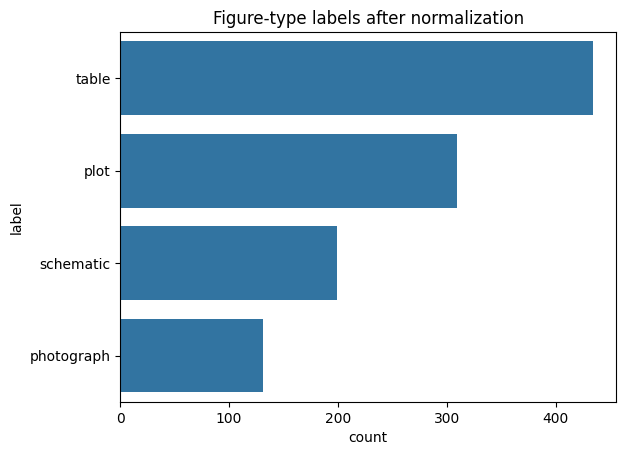

In [8]:
LABELS = ["plot", "schematic", "photograph", "table"]
df = fig_df[fig_df.label.isin(LABELS)].reset_index(drop=True)
print("Dropped as CONFLICT or OTHER:", len(fig_df) - len(df), "| kept:", len(df))

sns.countplot(data=df, y="label", order=df.label.value_counts().index)
plt.title("Figure-type labels after normalization")
plt.show()

### Checkpoint 3

Which classes are largest and smallest? Why are the `CONFLICT` and `OTHER` rows dropped instead of kept, and why should this lab report macro F1?

**Answer:** `table` is the largest class (434 captions) and `photograph` the smallest (131). The 18 `CONFLICT` rows are figure files annotated as tables, so their gold label is uncertain; the 24 `OTHER` rows are empty, "other", maps, or mixed types, too few and too heterogeneous to form a class. Both are dropped and the number is reported. Accuracy would be dominated by `table` and `plot`; macro F1 gives `photograph` the same weight as `table`.

## 4. One fixed split, grouped by paper

Every representation below is fitted on the same training papers and evaluated on the same test papers. Captions from one paper share model names, dataset names, and phrasing. A random caption-level split would let the model recognize the paper instead of the figure type. `StratifiedGroupKFold` keeps whole papers together while approximately preserving class proportions; its first fold (about 20%) is the test set.

In [9]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, df.label, groups=df.paper_id))
train_df, test_df = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
train_papers, test_papers = set(train_df.paper_id), set(test_df.paper_id)

print("Train / test captions:", len(train_df), len(test_df))
print("Train / test papers  :", len(train_papers), len(test_papers),
      "| shared papers:", len(train_papers & test_papers))
display(pd.DataFrame({"train": train_df.label.value_counts(normalize=True),
                      "test": test_df.label.value_counts(normalize=True)}).round(3))

# The text corpus used in Sections 5-9 follows the same paper split
corpus_train = text_df[text_df.paper_id.isin(train_papers)]
corpus_test = text_df[text_df.paper_id.isin(test_papers)]
print("Corpus texts train / test:", len(corpus_train), len(corpus_test))

Train / test captions: 857 216
Train / test papers  : 93 25 | shared papers: 0


,train,test
label,,
table,0.404,0.407
plot,0.288,0.287
schematic,0.186,0.185
photograph,0.123,0.120


Corpus texts train / test: 2483 630


### Checkpoint 4

Why is the split grouped by paper, and what does it cost?

**Answer:** Captions of the same paper repeat names such as a model acronym or a dataset. If one caption of a paper is in training and another in testing, the classifier can score well by memorizing paper-specific words, and the test score overstates performance on new papers. Grouping removes that shortcut. The cost is that class proportions are only approximately preserved and the test set depends on which 25 papers it contains. Section 10 measures how much a random split would inflate the score.

## 5. Cleaning: minimal, scientific, and aggressive

`clean_minimal` is the course default. `clean_scientific` adds only the steps that the audit justified: URL and LaTeX placeholders for the QA text, with HTML and mojibake repair as safety nets. `clean_alpha_only` is the aggressive baseline. Markup is removed before placeholders are inserted; in the opposite order the tag remover would delete the placeholders.

In [10]:
try:
    from ftfy import fix_text
except ImportError:
    fix_text = None

RE_URL  = re.compile(r"https?://\S+|www\.\S+")
RE_HTML = re.compile(r"</?[a-zA-Z][a-zA-Z0-9:-]*(?:\s[^<>]*?)?/?>")   # "<" must be followed by a letter: "a < b" survives
RE_CITE = re.compile(r"\\(?:cite[pt]?|ref|eqref|label)\s*\{[^}]*\}")
RE_MATH = re.compile(r"\$\$?.+?\$\$?", re.DOTALL)

def clean_minimal(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = re.sub(r"\s+", " ", text).strip()
    return text.lower()

def clean_scientific(text):
    text = str(text)
    if fix_text is not None:
        text = fix_text(text)              # mojibake repair: "TÃ¼rkiye" -> "Türkiye"
    text = unicodedata.normalize("NFKC", text)
    text = html.unescape(text)             # "&amp;" -> "&"
    text = RE_HTML.sub(" ", text)
    text = RE_URL.sub(" <url> ", text)
    text = RE_CITE.sub(" ", text)
    text = RE_MATH.sub(" <math> ", text)
    text = text.replace("\\", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text.lower()

def clean_alpha_only(text):
    text = clean_minimal(text)
    text = re.sub(r"[^a-z ]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

In [11]:
def first_match(series, pattern):
    # Shortest matching text, so the relevant part stays visible
    hits = series[series.str.contains(pattern, regex=True)]
    return hits.loc[hits.str.len().idxmin()] if len(hits) else None

examples = [
    first_match(df.caption, "[α-ω]"),
    first_match(df.caption, r"\d+(?:\.\d+)?\s?%"),
    first_match(text_df.text, r"https?://"),
    first_match(qa_df.explanation, r"\$"),
    "<p>Accuracy &amp; F1</p> on the TÃ¼rkiye split",   # synthetic: HTML entity, tags, mojibake
]
for x in [e for e in examples if e]:
    print("RAW       :", x[:200])
    print("MINIMAL   :", clean_minimal(x)[:200])
    print("SCIENTIFIC:", clean_scientific(x)[:200])
    print("ALPHA ONLY:", clean_alpha_only(x)[:200], "\n")

RAW       : Learning Curves Compared with Policy π1.
MINIMAL   : learning curves compared with policy π1.
SCIENTIFIC: learning curves compared with policy π1.
ALPHA ONLY: learning curves compared with policy 

RAW       : Table 10: Example from bAbI dialog Task 1 with 100% OOV.
MINIMAL   : table 10: example from babi dialog task 1 with 100% oov.
SCIENTIFIC: table 10: example from babi dialog task 1 with 100% oov.
ALPHA ONLY: table example from babi dialog task with oov 

RAW       : Table 5: Further results on http://changedetection.net.
MINIMAL   : table 5: further results on http://changedetection.net.
SCIENTIFIC: table 5: further results on <url>
ALPHA ONLY: table further results on http changedetection net 

RAW       : The RCV1 dataset shows the largest range of AMI values across the different values of $\power$, indicating that the performance of the algorithm on this dataset is highly dependent on the choice of $\
MINIMAL   : the rcv1 dataset shows the largest range of ami value

In [12]:
for name, fn in [("minimal", clean_minimal), ("scientific", clean_scientific), ("alpha only", clean_alpha_only)]:
    vocab = Counter(w for t in text_df.text for w in fn(t).split())
    print(f"{name:10s} vocabulary = {len(vocab):6,d}   tokens = {sum(vocab.values()):7,d}")

minimal    vocabulary = 11,261   tokens =  94,845
scientific vocabulary = 11,132   tokens =  94,920
alpha only vocabulary =  5,284   tokens =  94,586


### Checkpoint 5

List evidence that alphabetic-only cleaning deletes from captions, and name the classes it is most likely to hurt.

**Answer:** It deletes numbers and percentages, metric names that contain digits or symbols (`R@1`, `F1`), panel markers such as `(a)` and `(b)`, Greek letters, and the number in "Table 3". Numbers and metric names are typical of tables and plots, and panel markers of multi-panel plots and photograph grids. The vocabulary shrinks by more than half. Whether the deleted evidence matters for this classifier is an empirical question, which Section 10 answers.

## 6. Normalization: stemming and lemmatization

`WordNetLemmatizer.lemmatize(w)` treats every word as a noun when no part-of-speech tag is given, so `running` stays `running`. The words below are tagged in a sentence, because a POS tagger needs context.

In [13]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer

porter, lancaster, lemmatizer = PorterStemmer(), LancasterStemmer(), WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

sentence = ("The models were trained on studies of children who went running, "
            "while researchers were analyzing better relational embeddings.")
rows = []
for word, tag in nltk.pos_tag(word_tokenize(sentence)):
    if not word.isalpha():
        continue
    w = word.lower()
    rows.append({"word": w, "POS": tag, "Porter": porter.stem(w), "Lancaster": lancaster.stem(w),
                 "lemma (no POS)": lemmatizer.lemmatize(w),
                 "lemma (POS)": lemmatizer.lemmatize(w, penn_to_wordnet(tag))})
display(pd.DataFrame(rows))

,word,POS,Porter,Lancaster,lemma (no POS),lemma (POS)
0,the,DT,the,the,the,the
1,models,NNS,model,model,model,model
2,were,VBD,were,wer,were,be
3,trained,VBN,train,train,trained,train
4,on,IN,on,on,on,on
5,studies,NNS,studi,study,study,study
6,of,IN,of,of,of,of
7,children,NNS,children,childr,child,child
8,who,WP,who,who,who,who
9,went,VBD,went,went,went,go


In [14]:
TOKEN_RE = re.compile(r"<[a-z]+>|\w+(?:[-']\w+)*")
STOP = set(stopwords.words("english"))

def normalize_tokens(text, remove_stop=False, stem=None, lemma=None):
    tokens = TOKEN_RE.findall(clean_scientific(text))
    if remove_stop:
        tokens = [t for t in tokens if t not in STOP]
    if stem:
        stemmer = porter if stem == "porter" else lancaster
        tokens = [stemmer.stem(t) for t in tokens]
    if lemma == "no_pos":
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    if lemma == "pos":
        tokens = [lemmatizer.lemmatize(t, penn_to_wordnet(g)) for t, g in nltk.pos_tag(tokens)]
    return tokens

configs = {
    "lowercase only":         {},
    "+ stop-word removal":    {"remove_stop": True},
    "+ Porter stemming":      {"remove_stop": True, "stem": "porter"},
    "+ Lancaster stemming":   {"remove_stop": True, "stem": "lancaster"},
    "+ lemmatization, no POS": {"remove_stop": True, "lemma": "no_pos"},
    "+ lemmatization, POS":   {"remove_stop": True, "lemma": "pos"},
}
rows = []
for name, kw in configs.items():
    tokens = [t for c in df.caption for t in normalize_tokens(c, **kw)]
    rows.append({"normalization": name, "tokens": len(tokens), "vocabulary": len(set(tokens))})
display(pd.DataFrame(rows))

,normalization,tokens,vocabulary
0,lowercase only,33640,4618
1,+ stop-word removal,22326,4510
2,+ Porter stemming,22326,3430
3,+ Lancaster stemming,22326,3190
4,"+ lemmatization, no POS",22326,4090
5,"+ lemmatization, POS",22326,3854


### Checkpoint 6

Compare the two lemmatization rows with the stemming rows. Which method would you use before TF–IDF here, and which before a transformer tokenizer?

**Answer:** Without POS tags the lemmatizer only handles nouns: `studies` becomes `study`, but `running`, `analyzing`, and `were` keep their inflections, so the vocabulary shrinks less (4,090 types) than with POS tags (3,854), where `running` becomes `run`, `went` becomes `go`, and `were` becomes `be`. Tagging errors propagate: in this sentence the tagger labelled `better` as an adverb, so it became `well`. Lancaster cuts hardest and gives the smallest vocabulary (3,190), at the cost of conflating unrelated words (`better` becomes `bet`). With about 1,000 captions, a smaller vocabulary can reduce sparsity for TF–IDF, so POS-aware lemmatization is a reasonable option. Before a transformer tokenizer none of these steps is applied: the tokenizer was trained on raw text and expects inflected forms.

## 7. Sentence segmentation

In scientific text a period often does not end a sentence: `Fig. 3`, `et al.`, `i.e.`, `vs.`, `0.785`.

In [15]:
tricky = ("As shown in Fig. 3, the model of Wu et al. reaches 0.785 accuracy, i.e. a 2.1% gain. "
          "We compare it vs. the baseline in Table 1.")
print("SPLIT ON '.':", [s.strip() for s in tricky.split(".") if s.strip()], "\n")
print("PUNKT       :", sent_tokenize(tricky))

SPLIT ON '.': ['As shown in Fig', '3, the model of Wu et al', 'reaches 0', '785 accuracy, i', 'e', 'a 2', '1% gain', 'We compare it vs', 'the baseline in Table 1'] 

PUNKT       : ['As shown in Fig.', '3, the model of Wu et al.', 'reaches 0.785 accuracy, i.e.', 'a 2.1% gain.', 'We compare it vs. the baseline in Table 1.']


In [16]:
def rule_split(text):
    # Split after . ! ? followed by whitespace: handles decimals, fails on "Fig. 3" and "et al."
    return [s for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]

seg = text_df[text_df.source.isin(["caption", "explanation"])].copy()
seg["rule"] = seg.text.apply(lambda t: len(rule_split(t)))
seg["punkt"] = seg.text.apply(lambda t: len(sent_tokenize(t)))
display(seg.groupby("source")[["rule", "punkt"]].sum())

disagree = seg[seg.rule != seg.punkt]
print("Texts where the two segmenters disagree:", len(disagree))
if len(disagree):
    example = disagree.text.iloc[0]
    print("\nTEXT :", example[:300])
    print("RULE :", rule_split(example))
    print("PUNKT:", sent_tokenize(example))

,rule,punkt
source,,
caption,2610,2601
explanation,1689,1699


Texts where the two segmenters disagree: 64

TEXT : Empirical comparison of DILNets, DMRNets, and ResNets. The average classification error from 5 runs and the standard deviation (mean ± std.) are reported. Refer to Table 1 for network structure descriptions.
RULE : ['Empirical comparison of DILNets, DMRNets, and ResNets.', 'The average classification error from 5 runs and the standard deviation (mean ± std.) are reported.', 'Refer to Table 1 for network structure descriptions.']
PUNKT: ['Empirical comparison of DILNets, DMRNets, and ResNets.', 'The average classification error from 5 runs and the standard deviation (mean ± std.)', 'are reported.', 'Refer to Table 1 for network structure descriptions.']


### Checkpoint 7

Read the disagreement example. Which segmenter is right, and does segmentation matter for this lab's classifier?

**Answer:** Neither is reliable everywhere. The punctuation rule splits after every abbreviation, such as `Fig.` or `et al.`; Punkt has learned common abbreviations but can still split after rarer ones, such as `std.)` in this run's example. Over captions and explanations the two disagree on 64 texts, about 4% of them. The classifier reads whole captions, so segmentation errors do not affect it; they matter when sentences are the unit of work, for example when retrieving the sentence of an explanation that supports an answer.

## 8. Word, character, and subword tokenization

In [17]:
regex_tok = RegexpTokenizer(r"<[a-z]+>|\w+(?:[-']\w+)*|\S")

s = "We don't use state-of-the-art CNNs; R@1 improves by 2.1% (see Table 2)."
print("whitespace:", s.split())
print("regex     :", regex_tok.tokenize(s))
print("nltk      :", word_tokenize(s))

whitespace: ['We', "don't", 'use', 'state-of-the-art', 'CNNs;', 'R@1', 'improves', 'by', '2.1%', '(see', 'Table', '2).']
regex     : ['We', "don't", 'use', 'state-of-the-art', 'CNNs', ';', 'R', '@', '1', 'improves', 'by', '2', '.', '1', '%', '(', 'see', 'Table', '2', ')', '.']
nltk      : ['We', 'do', "n't", 'use', 'state-of-the-art', 'CNNs', ';', 'R', '@', '1', 'improves', 'by', '2.1', '%', '(', 'see', 'Table', '2', ')', '.']


In [18]:
def word_tokens(text):
    return regex_tok.tokenize(clean_scientific(text))

def char_tokens(text):
    return list(clean_scientific(text))

rows = []
for level, fn in [("word", word_tokens), ("character", char_tokens)]:
    seqs = [fn(t) for t in corpus_train.text]
    flat = [x for seq in seqs for x in seq]
    rows.append({"level": level, "vocabulary": len(set(flat)), "tokens": len(flat),
                 "mean tokens per text": round(np.mean([len(seq) for seq in seqs]), 1)})
display(pd.DataFrame(rows))

,level,vocabulary,tokens,mean tokens per text
0,word,5615,88068,35.5
1,character,123,461341,185.8


In [19]:
# Out-of-vocabulary rate: vocabulary built on training papers, measured on test papers
train_vocab = Counter(w for t in corpus_train.text for w in word_tokens(t))
test_tokens = [w for t in corpus_test.text for w in word_tokens(t)]
print(f"Training vocabulary: {len(train_vocab):,} types | test tokens: {len(test_tokens):,}")

rows = []
for cap in [500, 1000, 2000, 5000, len(train_vocab)]:
    kept = {w for w, _ in train_vocab.most_common(cap)}
    rows.append({"vocabulary cap": cap,
                 "test OOV rate (%)": round(100 * np.mean([w not in kept for w in test_tokens]), 2)})
display(pd.DataFrame(rows))

unseen = Counter(w for w in test_tokens if w not in train_vocab)
print("Most frequent unseen test words:", unseen.most_common(15))

Training vocabulary: 5,615 types | test tokens: 24,915


,vocabulary cap,test OOV rate (%)
0,500,26.25
1,1000,19.66
2,2000,14.12
3,5000,9.07
4,5615,8.54


Most frequent unseen test words: [('state-action', 32), ('gbi', 21), ('c-tarone', 20), ('landscape', 20), ('devon', 18), ('visual7w', 18), ('binarization', 17), ('decoys', 17), ('agent', 16), ('cvr', 16), ('ft', 15), ('phrase', 15), ('places', 15), ('place-based', 15), ('landscapes', 14)]


Subword tokenizers remove the OOV problem by splitting unknown words into known pieces. The three models below use the three algorithms from the lecture: WordPiece (BERT), byte-level BPE (GPT-2), and Unigram via SentencePiece (T5).

In [20]:
from transformers import AutoTokenizer

tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")   # WordPiece
tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")                # byte-level BPE
tok_t5   = AutoTokenizer.from_pretrained("t5-small")            # Unigram (SentencePiece)
TOKENIZERS = [("BERT (WordPiece)", tok_bert), ("GPT-2 (byte-level BPE)", tok_gpt2), ("T5 (Unigram)", tok_t5)]

token_examples = [
    "The researchers are analyzing unexplainable models.",
    test_df.caption.iloc[0],
    "Precision@10 improves when λ = 0.5",
    "Unknown symbol: ꙮ",
]
for x in token_examples:
    print("\nTEXT:", x[:120])
    for name, tk in TOKENIZERS:
        print(f"  {name:24s}", tk.tokenize(x)[:18])
    print(f"  {'BERT input_ids':24s}", tok_bert(x)["input_ids"][:18])


TEXT: The researchers are analyzing unexplainable models.
  BERT (WordPiece)         ['the', 'researchers', 'are', 'analyzing', 'une', '##x', '##pl', '##aina', '##ble', 'models', '.']
  GPT-2 (byte-level BPE)   ['The', 'Ġresearchers', 'Ġare', 'Ġanalyzing', 'Ġunex', 'plain', 'able', 'Ġmodels', '.']
  T5 (Unigram)             ['▁The', '▁researchers', '▁are', '▁', 'analyzing', '▁une', 'x', 'plain', 'able', '▁models', '.']
  BERT input_ids           [101, 1996, 6950, 2024, 20253, 16655, 2595, 24759, 27971, 3468, 4275, 1012, 102]

TEXT: Our general loss function (left) and its gradient (right) for different values of its shape parameter α. Several values 
  BERT (WordPiece)         ['our', 'general', 'loss', 'function', '(', 'left', ')', 'and', 'its', 'gradient', '(', 'right', ')', 'for', 'different', 'values', 'of', 'its']
  GPT-2 (byte-level BPE)   ['Our', 'Ġgeneral', 'Ġloss', 'Ġfunction', 'Ġ(', 'left', ')', 'Ġand', 'Ġits', 'Ġgradient', 'Ġ(', 'right', ')', 'Ġfor', 'Ġdifferent', 'Ġvalues'

In [21]:
batch = tok_bert(["short caption", "a much longer caption about the results"],
                 padding=True, return_tensors="np")
print("input_ids:\n", batch["input_ids"])
print("attention_mask:\n", batch["attention_mask"])

input_ids:
 [[  101  2460 14408  3258   102     0     0     0     0     0]
 [  101  1037  2172  2936 14408  3258  2055  1996  3463   102]]
attention_mask:
 [[1 1 1 1 1 0 0 0 0 0]
 [1 1 1 1 1 1 1 1 1 1]]


In [22]:
# Fertility = subword tokens per word on the test papers (lower = the tokenizer fits the domain better)
test_texts = corpus_test.text.tolist()
n_words = sum(len(regex_tok.tokenize(t)) for t in test_texts)

fertility = []
for name, tk in TOKENIZERS:
    pieces = [p for t in test_texts for p in tk.tokenize(t)]
    fertility.append({"tokenizer": name, "vocabulary": tk.vocab_size, "tokens": len(pieces),
                      "fertility": round(len(pieces) / n_words, 3),
                      "unknown tokens": sum(p == tk.unk_token for p in pieces)})
display(pd.DataFrame(fertility))

,tokenizer,vocabulary,tokens,fertility,unknown tokens
0,BERT (WordPiece),30522,28929,1.153,3
1,GPT-2 (byte-level BPE),50257,28448,1.134,0
2,T5 (Unigram),32100,30857,1.230,0


### Checkpoint 8

Using the outputs above, record for one domain term, one number, one Greek symbol, and one rare symbol whether each stays whole, splits into subwords, or becomes an unknown token.

**Answer:** The domain term `unexplainable` splits in all three tokenizers (BERT: `une ##x ##pl ##aina ##ble`; GPT-2: `unex plain able`). BERT and GPT-2 split `0.5` at the decimal point, while T5 keeps it whole. `λ` stays whole in BERT, but GPT-2 splits it into two byte tokens. The rare symbol `ꙮ` becomes `[UNK]` in BERT, so its information is lost. GPT-2 never produces an unknown token: its byte-level base vocabulary covers all 256 byte values, so `ꙮ` falls back to three byte tokens. T5 prints `ꙮ` as a piece, but the character is not in its vocabulary, so its input ID is the unknown ID (check with `tok_t5.convert_tokens_to_ids(["ꙮ"])`). The "unknown tokens" column counts string pieces and therefore misses T5's unknowns; counting IDs equal to `tk.unk_token_id` would catch them. The same text thus has a different length, and a different information loss, under each tokenizer.

## 9. Byte-Pair Encoding by hand

The `tokenizers` library trains BPE in one call and hides the mechanism. The functions below implement the algorithm from the lecture. Every word is split into characters and ends with the end-of-word marker `</w>`. The most frequent adjacent pair is merged, and the step repeats until the target number of merges is reached.

In [23]:
def get_pair_counts(vocab):
    pairs = Counter()
    for word, freq in vocab.items():
        symbols = word.split()
        for a, b in zip(symbols, symbols[1:]):
            pairs[(a, b)] += freq
    return pairs

def merge_pair(pair, vocab):
    pattern = re.compile(r"(?<!\S)" + re.escape(" ".join(pair)) + r"(?!\S)")
    return {pattern.sub("".join(pair), word): freq for word, freq in vocab.items()}

def bpe_trace(word_freqs, num_merges, show=True):
    vocab = {" ".join(word) + " </w>": freq for word, freq in word_freqs.items()}
    if show:
        print("Base vocabulary:", sorted({s for w in vocab for s in w.split()}))
        for w, f in vocab.items():
            print(f"   {w:<22} {f}")
        print()
    merges = []
    for step in range(1, num_merges + 1):
        pairs = get_pair_counts(vocab)
        if not pairs:
            break
        (a, b), count = pairs.most_common(1)[0]
        tied = sum(c == count for c in pairs.values()) > 1
        vocab = merge_pair((a, b), vocab)
        merges.append(((a, b), count))
        if show:
            note = "   (tie: the first pair seen wins)" if tied else ""
            print(f"Merge {step}: {a!r} + {b!r} -> {a + b!r}  frequency {count}{note}")
            print("   ", list(vocab))
    return merges, vocab

In [24]:
# Corpus from the lecture slides
merges, _ = bpe_trace({"low": 5, "lower": 2, "newest": 6, "widest": 3}, num_merges=3)
print("\nLearned rules:", [a + b for (a, b), _ in merges], "-> the suffix '-est' emerges from the data")

Base vocabulary: ['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']
   l o w </w>             5
   l o w e r </w>         2
   n e w e s t </w>       6
   w i d e s t </w>       3

Merge 1: 'e' + 's' -> 'es'  frequency 9   (tie: the first pair seen wins)
    ['l o w </w>', 'l o w e r </w>', 'n e w es t </w>', 'w i d es t </w>']
Merge 2: 'es' + 't' -> 'est'  frequency 9   (tie: the first pair seen wins)
    ['l o w </w>', 'l o w e r </w>', 'n e w est </w>', 'w i d est </w>']
Merge 3: 'est' + '</w>' -> 'est</w>'  frequency 9
    ['l o w </w>', 'l o w e r </w>', 'n e w est</w>', 'w i d est</w>']

Learned rules: ['es', 'est', 'est</w>'] -> the suffix '-est' emerges from the data


In [25]:
# Assessment question from the slides: first two merges for {talk: 4, tall: 3, thin: 2}
merges, _ = bpe_trace({"talk": 4, "tall": 3, "thin": 2}, num_merges=2, show=False)
print("First two merges:", [f"{a}+{b} -> {a + b} ({c})" for (a, b), c in merges])

First two merges: ['t+a -> ta (7)', 'ta+l -> tal (7)']


In [26]:
# The same algorithm on the 60 most frequent words of the training corpus
top_words = Counter(w for t in corpus_train.text for w in word_tokens(t) if w.isalpha())
merges, _ = bpe_trace(dict(top_words.most_common(60)), num_merges=10, show=False)
for step, ((a, b), c) in enumerate(merges, 1):
    print(f"{step:2d}. {a!r} + {b!r} -> {a + b!r}   frequency {c}")

 1. 'e' + '</w>' -> 'e</w>'   frequency 10417
 2. 't' + 'h' -> 'th'   frequency 10314
 3. 'th' + 'e</w>' -> 'the</w>'   frequency 7614
 4. 's' + '</w>' -> 's</w>'   frequency 3851
 5. 'n' + '</w>' -> 'n</w>'   frequency 2894
 6. 't' + '</w>' -> 't</w>'   frequency 2703
 7. 'd' + '</w>' -> 'd</w>'   frequency 2503
 8. 'o' + 'f' -> 'of'   frequency 2396
 9. 'of' + '</w>' -> 'of</w>'   frequency 2396
10. 'a' + 'n' -> 'an'   frequency 2356


In [27]:
# Train a byte-level BPE tokenizer on the training papers only, then measure it on the test papers
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

own_bpe = Tokenizer(models.BPE(unk_token="<unk>"))
own_bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
own_bpe.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=8000, min_frequency=2, special_tokens=["<pad>", "<unk>"],
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
own_bpe.train_from_iterator(corpus_train.text.tolist(), trainer)

pieces = [p for t in test_texts for p in own_bpe.encode(t).tokens]
fertility.append({"tokenizer": "SPIQA BPE (trained here)", "vocabulary": own_bpe.get_vocab_size(),
                  "tokens": len(pieces), "fertility": round(len(pieces) / n_words, 3),
                  "unknown tokens": sum(p == "<unk>" for p in pieces)})
display(pd.DataFrame(fertility).sort_values("fertility"))

enc = own_bpe.encode("unexplainable models")
print("tokens:", enc.tokens, "\nids   :", enc.ids)

,tokenizer,vocabulary,tokens,fertility,unknown tokens
1,GPT-2 (byte-level BPE),50257,28448,1.134,0
0,BERT (WordPiece),30522,28929,1.153,3
3,SPIQA BPE (trained here),7671,30723,1.225,0
2,T5 (Unigram),32100,30857,1.230,0


tokens: ['Ġun', 'ex', 'plain', 'able', 'Ġmodels'] 
ids   : [709, 645, 3148, 353, 546]


### Checkpoint 9

Why does BPE need the `</w>` marker? Compare the tokenizer trained here with GPT-2 on the test papers: is lower fertility enough to prefer a tokenizer?

**Answer:** Without `</w>`, the symbol `est` would stand for both the suffix in "newest" and the letters inside "establish"; the marker keeps word-final pieces distinct. A tokenizer trained on in-domain text turns frequent domain words into single tokens, but this one saw only about 2,500 texts from 93 papers. On the 25 unseen test papers it needs more tokens per word (1.225) than GPT-2 (1.134) and BERT (1.153); only T5 (1.230) is worse. The names and terms of new papers were never merged, while the pretrained vocabularies cover general scientific English far better. Fertility measured on the texts a tokenizer was trained on would look much better, which is why it is measured on held-out papers here. Even a lower fertility would not be enough on its own: a pretrained model works only with the tokenizer it was trained with, so a new tokenizer means training a model from scratch.

## 10. TF–IDF baseline

              precision    recall  f1-score   support

        plot      0.721     0.710     0.715        62
   schematic      0.674     0.775     0.721        40
  photograph      0.750     0.462     0.571        26
       table      0.817     0.864     0.840        88

    accuracy                          0.755       216
   macro avg      0.741     0.702     0.712       216
weighted avg      0.755     0.755     0.750       216



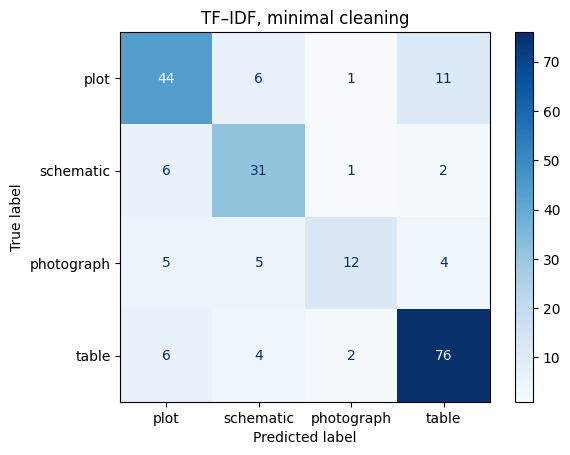

In [28]:
def make_tfidf_pipeline(preprocessor):
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=preprocessor, ngram_range=(1, 2),
                                  min_df=2, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
    ])

model_min = make_tfidf_pipeline(clean_minimal).fit(train_df.caption, train_df.label)
pred_min = model_min.predict(test_df.caption)
print(classification_report(test_df.label, pred_min, labels=LABELS, digits=3))
ConfusionMatrixDisplay.from_predictions(test_df.label, pred_min, labels=LABELS, cmap="Blues")
plt.title("TF–IDF, minimal cleaning")
plt.show()

In [29]:
model_sci = make_tfidf_pipeline(clean_scientific).fit(train_df.caption, train_df.label)
pred_sci = model_sci.predict(test_df.caption)
model_alpha = make_tfidf_pipeline(clean_alpha_only).fit(train_df.caption, train_df.label)
pred_alpha = model_alpha.predict(test_df.caption)

for name, pred in [("minimal", pred_min), ("scientific", pred_sci), ("alpha only", pred_alpha)]:
    print(f"{name:11s} accuracy = {accuracy_score(test_df.label, pred):.3f}   "
          f"macro F1 = {f1_score(test_df.label, pred, average='macro'):.3f}")

minimal     accuracy = 0.755   macro F1 = 0.712
scientific  accuracy = 0.755   macro F1 = 0.712
alpha only  accuracy = 0.759   macro F1 = 0.712


In [30]:
cm = confusion_matrix(test_df.label, pred_min, labels=LABELS)
np.fill_diagonal(cm, 0)
pairs = [{"actual": LABELS[i], "predicted": LABELS[j], "count": cm[i, j]}
         for i, j in zip(*np.unravel_index(np.argsort(cm.ravel())[::-1][:6], cm.shape))]
display(pd.DataFrame(pairs))

vec, clf = model_min.named_steps["tfidf"], model_min.named_steps["clf"]
names = np.array(vec.get_feature_names_out())
display(pd.DataFrame({label: names[np.argsort(clf.coef_[i])[-12:]][::-1]
                      for i, label in enumerate(clf.classes_)}))

,actual,predicted,count
0,plot,table,11
1,table,plot,6
2,schematic,plot,6
3,plot,schematic,6
4,photograph,schematic,5
5,photograph,plot,5


,photograph,plot,schematic,table
0,examples,curves,an,table
1,images,accuracy,architecture,datasets
2,generated,error,network,comparison
3,examples of,versus,overview of,table the
4,top,axis,overview,results
5,face,distribution,graph,statistics
6,body,number of,illustration,evaluation
7,row,with,structure,on
8,bottom,time,illustration of,dataset
9,sample,number,vector,models


### Checkpoint 10

Did scientific or alphabetic-only cleaning change macro F1? Which pair is confused most often, and what do the strongest `table` features reveal?

**Answer:** Scientific cleaning gives exactly the same predictions as minimal cleaning, as the audit predicted: at caption level it only replaces five URLs. Alphabetic-only cleaning halves the vocabulary yet leaves macro F1 practically unchanged: deleting numbers removed information, but not information this classifier relied on, because words such as `results`, `accuracy`, and `examples` already separate the classes. Deleting evidence and losing accuracy are separate questions, and each must be measured. The most frequent confusion is `plot` predicted as `table`: result plots and result tables share words such as "results", "accuracy", and "comparison". `photograph` has the lowest recall, and its errors go to `schematic` and `plot`. The strongest `table` features include `table` and the bigram `table the`, produced by captions that start with "Table N: The"; the model partly learns the citation format. Some features are paper-specific, such as `hamilton` for photographs: they fit the training papers and cannot transfer, which is why the split is grouped.

In [31]:
# Why the split is grouped: the same pipeline on a random caption-level split of equal size
rand_train, rand_test = train_test_split(df, test_size=len(test_df), random_state=SEED, stratify=df.label)
pred_rand = make_tfidf_pipeline(clean_minimal).fit(rand_train.caption, rand_train.label).predict(rand_test.caption)
shared = len(set(rand_train.paper_id) & set(rand_test.paper_id))
print(f"Random caption split: macro F1 = {f1_score(rand_test.label, pred_rand, average='macro'):.3f}"
      f"   ({shared} papers on both sides)")
print(f"Grouped paper split : macro F1 = {f1_score(test_df.label, pred_min, average='macro'):.3f}"
      f"   (0 papers on both sides)")

Random caption split: macro F1 = 0.814   (93 papers on both sides)
Grouped paper split : macro F1 = 0.712   (0 papers on both sides)


## 11. Contextual sentence embeddings

The encoder reads the raw caption; no cleaning function is applied, because its tokenizer expects natural text. `all-MiniLM-L6-v2` truncates inputs at 256 word pieces, which affects only the longest captions.

In [32]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
X_train_emb = encoder.encode(train_df.caption.tolist(), batch_size=64,
                             show_progress_bar=True, normalize_embeddings=True)
X_test_emb = encoder.encode(test_df.caption.tolist(), batch_size=64,
                            show_progress_bar=True, normalize_embeddings=True)
print("Train / test embedding matrices:", X_train_emb.shape, X_test_emb.shape)

emb_clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
emb_clf.fit(X_train_emb, train_df.label)
pred_emb = emb_clf.predict(X_test_emb)
print(classification_report(test_df.label, pred_emb, labels=LABELS, digits=3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Train / test embedding matrices: (857, 384) (216, 384)
              precision    recall  f1-score   support

        plot      0.811     0.694     0.748        62
   schematic      0.544     0.775     0.639        40
  photograph      0.577     0.577     0.577        26
       table      0.900     0.818     0.857        88

    accuracy                          0.745       216
   macro avg      0.708     0.716     0.705       216
weighted avg      0.770     0.745     0.752       216



## 12. Compare experiments and inspect errors

In [33]:
def score_row(experiment, preprocessing, representation, pred):
    return {"experiment": experiment, "preprocessing": preprocessing, "representation": representation,
            "accuracy": accuracy_score(test_df.label, pred),
            "macro_f1": f1_score(test_df.label, pred, average="macro")}

results = pd.DataFrame([
    score_row("A", "minimal", "TF–IDF (1,2)", pred_min),
    score_row("B", "scientific", "TF–IDF (1,2)", pred_sci),
    score_row("C", "alpha only", "TF–IDF (1,2)", pred_alpha),
    score_row("D", "raw caption", "MiniLM embeddings", pred_emb),
]).round(3)
display(results.sort_values("macro_f1", ascending=False))

,experiment,preprocessing,representation,accuracy,macro_f1
0,A,minimal,"TF–IDF (1,2)",0.755,0.712
1,B,scientific,"TF–IDF (1,2)",0.755,0.712
2,C,alpha only,"TF–IDF (1,2)",0.759,0.712
3,D,raw caption,MiniLM embeddings,0.745,0.705


In [34]:
errors = test_df[["paper_id", "caption", "label"]].copy()
errors["tfidf"] = pred_min
errors["embedding"] = pred_emb
wrong = errors[(errors.label != errors.tfidf) | (errors.label != errors.embedding)]
print("Test captions misclassified by at least one model:", len(wrong), "of", len(errors))
print("Misclassified by both:", ((errors.label != errors.tfidf) & (errors.label != errors.embedding)).sum())
display(wrong.head(12))

Test captions misclassified by at least one model: 76 of 216
Misclassified by both: 32


,paper_id,caption,label,tfidf,embedding
49,1701.03077v10,Monocular depth estimation results on the KITTI benchmark using the “Baseline” network of [42]. Replacing only the network’s loss function with our “adaptive” loss over wavelet...,photograph,table,photograph
50,1701.03077v10,"Table 2. Results on unsupervised monocular depth estimation using the KITTI dataset [13], building upon the model from [42] (“Baseline”). By replacing the per-pixel loss used b...",table,table,photograph
52,1701.03077v10,The final shape parameters α for our unsupervised monocular depth estimation model trained on KITTI data. The parameters are visualized in the same “YUV + Wavelet” output space...,plot,schematic,photograph
56,1701.03077v10,"As is common practice, the VAE samples shown in this paper are samples from the latent space (left) but not from the final conditional distribution (right). Here we contrast de...",photograph,schematic,schematic
57,1701.03077v10,The final shape and scale parameters {α(i)} and {c(i)} for our “Pixels + RGB” VAE after training has converged. We visualize α with black=0 and white=2 and log(c) with black=lo...,photograph,plot,schematic
58,1701.03077v10,Monocular depth estimation results on the KITTI benchmark using the “Baseline” network of [42] and our own variant in which we replace the network’s loss function with our own ...,photograph,plot,photograph
65,1701.03077v10,Table 1. Validation set ELBOs (higher is better) for our variational autoencoders. Models using our general distribution better maximize the likelihood of unseen data than thos...,table,table,photograph
67,1701.03077v10,"Random samples (more precisely, means of the output distributions decoded from random samples in our latent space) from our family of trained variational autoencoders.",photograph,schematic,schematic
86,1603.00286v5,Fig. 5 The points in the blue trapezoid are mapped to the points on the blue interval at the bottom side of the polygon; each point in the trapezoid is mapped to the point just...,schematic,schematic,plot
88,1603.00286v5,"Fig. 4 Allocation-completion with n = 4 original pieces and b = 1 blank, denoted Z′5.",schematic,photograph,schematic


### Checkpoint 11

Select two errors from the table. For each, decide whether the likely cause is a short or generic caption, overlap between figure types, a noisy gold label, or missing vocabulary. Propose one change for each.

**Answer:** Typical patterns in this data: very short captions such as "Architecture of X" carry almost no type evidence; multi-panel figures combine photographs with plots, so either label is defensible; some gold labels came from a noisy annotator (Section 3); and photograph captions describe what the image shows ("examples of outputs") rather than naming the visual type. Useful changes are adding the text of the questions that reference the figure, merging or relabelling mixed figures, and auditing gold labels for the misclassified rows before tuning the model.

## Experiment record

Complete this table from the `results` table and the capstone below. Keep the split fixed for every row.

| Experiment | Preprocessing | Representation | Macro F1 | Observation |
|---|---|---|---:|---|
| A | Minimal | TF–IDF (1,2) |  |  |
| B | Scientific | TF–IDF (1,2) |  |  |
| C | Alpha only | TF–IDF (1,2) |  |  |
| D | Raw caption | MiniLM embeddings |  |  |
| E | Minimal, prefix removed | TF–IDF (1,2) |  |  |

## Capstone: with versus without the caption prefix

**Hypothesis:** The "Figure N:" / "Table N:" prefix leaks the label. A caption that starts with "Table" is almost certainly a table, but that tells us nothing about whether the model understands caption content, and a different PDF parser may strip the prefix.

Train the same TF–IDF pipeline with the prefix removed from both training and test captions. Keep the split, the vectorizer, and the classifier fixed. Report macro F1, per-class F1, and the predictions that change.

In [35]:
PREFIX = re.compile(r"^\s*(?:fig(?:ure)?|tab(?:le)?)\.?\s*\d+[a-z]?\s*[:.\-–]?\s*", re.IGNORECASE)

def clean_no_prefix(text):
    return clean_minimal(PREFIX.sub("", str(text)))

display(df.assign(has_prefix=df.caption.str.match(PREFIX))
          .groupby("label").has_prefix.mean().round(3).to_frame("share with prefix"))
example = test_df.caption[test_df.caption.str.match(PREFIX)].iloc[0]
print("BEFORE:", example[:110])
print("AFTER :", clean_no_prefix(example)[:110])

,share with prefix
label,
photograph,0.328
plot,0.204
schematic,0.327
table,0.666


BEFORE: Table 2. Results on unsupervised monocular depth estimation using the KITTI dataset [13], building upon the mo
AFTER : results on unsupervised monocular depth estimation using the kitti dataset [13], building upon the model from 


In [36]:
model_noprefix = make_tfidf_pipeline(clean_no_prefix).fit(train_df.caption, train_df.label)
pred_noprefix = model_noprefix.predict(test_df.caption)

capstone = pd.DataFrame({
    "with prefix": f1_score(test_df.label, pred_min, labels=LABELS, average=None),
    "without prefix": f1_score(test_df.label, pred_noprefix, labels=LABELS, average=None)},
    index=LABELS)
capstone.loc["macro F1"] = [f1_score(test_df.label, pred_min, average="macro"),
                            f1_score(test_df.label, pred_noprefix, average="macro")]
capstone["change"] = capstone["without prefix"] - capstone["with prefix"]
display(capstone.round(3))

changed = test_df.assign(with_prefix=pred_min, without_prefix=pred_noprefix)
changed = changed[changed.with_prefix != changed.without_prefix]
print("Predictions that changed:", len(changed),
      "| now correct:", (changed.without_prefix == changed.label).sum(),
      "| now wrong:", (changed.with_prefix == changed.label).sum())
display(changed[["caption", "label", "with_prefix", "without_prefix"]].head(10))

,with prefix,without prefix,change
plot,0.715,0.632,-0.084
schematic,0.721,0.705,-0.016
photograph,0.571,0.585,0.014
table,0.840,0.741,-0.099
macro F1,0.712,0.666,-0.046


Predictions that changed: 27 | now correct: 4 | now wrong: 18


,caption,label,with_prefix,without_prefix
59,Figure 9. Here we compare the validation set ELBO of our adaptive “Wavelets + YUV” VAE model with the ELBO achieved when setting all wavelet coefficients to have the same fixed...,plot,plot,table
88,"Fig. 4 Allocation-completion with n = 4 original pieces and b = 1 blank, denoted Z′5.",schematic,photograph,plot
89,Table 1 Worst-case number of blanks in a maximal arrangement of pairwise-disjoint Spieces contained in a cake C. From Akopyan and Segal-Halevi (2018).,table,table,plot
90,"Fig. 1 With geometric constraints, an efficient allocation might leave some cake unallocated. All figures were made with GeoGebra 5 (Hohenwarter et al., 2013).",schematic,schematic,table
126,"Figure 1: Left figure: the profile of the word vector L2norms as a function of log(fw) for each vocabulary word w, as learnt by our unigram model trained on Toronto books. Righ...",plot,schematic,plot
133,Table 4. Results on KITTI. (ft) denotes the fine-tuning. EPE denotes end-point error. Fl-all denotes the ratio of pixels where the flow estimate is incorrect by both ≥ 3 pixels...,table,table,plot
136,FlyingChairs (validation set). Green arrows indicate the small object that moves fast.,photograph,plot,table
138,KITTI 2015 (training set). Green arrows indicate the small object that moves fast.,photograph,plot,table
141,Table 6. Runtime (ms).,table,table,plot
144,Relation module R. C1 ∼ C5 denote the deformable cost volumes. k1 ∼ k5 denote the neighborhood sizes. r1 ∼ r5 denote the dilation rates. Concat denotes concatenation. Norm deno...,schematic,plot,table


**Interpretation:** Removing the prefix lowers macro F1 by about five points. The loss is concentrated in `table`, which loses its strongest cue ("Table N" opens about two thirds of table captions), and in `plot`: without "Figure N", result plots that share words such as "results" and "comparison" with tables drift towards `table`. The baseline score therefore partly measures the citation format. The score without the prefix is the more honest estimate of how well caption content identifies the figure type, and it is the one to report if captions may arrive without numbering.

## Student conclusion

Write 5–7 sentences stating which preprocessing and representation you would choose, which class remains difficult, what evidence supports the choice, and one limitation of the experiment.

**Model conclusion:** On the grouped split the two representations are practically tied: macro F1 is 0.712 for TF–IDF and 0.705 for MiniLM, a gap far smaller than the noise of a 216-caption test set. TF–IDF is the better default here because it is faster and its features can be inspected; MiniLM recovers more photographs (recall 0.58 against 0.46) but loses on schematics. The audit showed that captions in this split contain no LaTeX or HTML, so scientific cleaning produced exactly the same predictions as minimal cleaning, and alphabetic-only cleaning halved the vocabulary without changing macro F1: deleting information and losing accuracy are separate questions that must each be measured. `photograph` is the hardest class for TF–IDF, because its captions describe image content instead of naming the visual type, and result plots are most often mistaken for tables. Two forms of leakage inflate naive scores: paper overlap between train and test (a random split scores about ten points higher) and the "Table N:" prefix (removing it costs about five points, mostly in `table` and `plot`). The main limitation is size: 216 test captions from 25 papers make every score unstable, so the conclusion rests on per-class results and inspected errors as well as on macro F1.

## Optional extensions

1. Try character n-grams: `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`.
2. Repeat Section 11 with prefix-free captions: does MiniLM rely on the prefix too?
3. Append the questions that reference each figure (`qa_df.reference`) to its caption and test whether the added text helps `photograph`.
4. Repeat the grouped split with the other four folds and report the mean and spread of macro F1.